In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [23]:
peliculas = pd.read_csv("/content/netflix_movies_detailed_up_to_2025.csv")
series = pd.read_csv("/content/netflix_tv_shows_detailed_up_to_2025.csv")

In [24]:
peliculas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       16000 non-null  int64  
 1   type          16000 non-null  object 
 2   title         16000 non-null  object 
 3   director      15868 non-null  object 
 4   cast          15796 non-null  object 
 5   country       15534 non-null  object 
 6   date_added    16000 non-null  object 
 7   release_year  16000 non-null  int64  
 8   rating        16000 non-null  float64
 9   duration      0 non-null      float64
 10  genres        15893 non-null  object 
 11  language      16000 non-null  object 
 12  description   15868 non-null  object 
 13  popularity    16000 non-null  float64
 14  vote_count    16000 non-null  int64  
 15  vote_average  16000 non-null  float64
 16  budget        16000 non-null  int64  
 17  revenue       16000 non-null  int64  
dtypes: float64(4), int64(5), o

In [25]:
series.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       16000 non-null  int64  
 1   type          16000 non-null  object 
 2   title         16000 non-null  object 
 3   director      5035 non-null   object 
 4   cast          14843 non-null  object 
 5   country       14203 non-null  object 
 6   date_added    16000 non-null  object 
 7   release_year  16000 non-null  int64  
 8   rating        16000 non-null  float64
 9   duration      16000 non-null  object 
 10  genres        15026 non-null  object 
 11  language      16000 non-null  object 
 12  description   12794 non-null  object 
 13  popularity    16000 non-null  float64
 14  vote_count    16000 non-null  int64  
 15  vote_average  16000 non-null  float64
dtypes: float64(3), int64(3), object(10)
memory usage: 2.0+ MB


In [26]:
print(f"Series mas populares: {series["popularity"].max()}")
print(f"Series menos populares: {series["popularity"].min()}")
print(f"Películas mas populares: {peliculas["popularity"].max()}")
print(f"Películas menos populares: {peliculas["popularity"].min()}")

print(f"\nSeries con mayor valoración: {series["vote_average"].max()}")
print(f"Series con menor valoración: {series["vote_average"].min()}")
print(f"Películas con mayor valoración: {peliculas["vote_average"].max()}")
print(f"Películas con menor valoración: {peliculas["vote_average"].min()}")

Series mas populares: 6421.923
Series menos populares: 2.323
Películas mas populares: 3876.006
Películas menos populares: 3.86

Series con mayor valoración: 10.0
Series con menor valoración: 0.0
Películas con mayor valoración: 10.0
Películas con menor valoración: 0.0


In [27]:
def identificar_joyas(df, nombre_tipo, min_votos=30, q_pop=0.50, min_rating=7.5):
    """Filtra y etiqueta el catálogo según el cuadrante de alta valoración y baja popularidad."""
    df_clean = df.copy()

    # Conversión numérica de variables clave
    for col in ['popularity', 'vote_average', 'vote_count']:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

    # Filtro de representatividad (Regla metodológica contra notas infladas artificiales)
    df_clean = df_clean[df_clean['vote_count'] >= min_votos].dropna(subset=['popularity', 'vote_average'])

    # Cortes estadísticos objetivos
    corte_pop = df_clean['popularity'].quantile(q_pop)

    # Segmentación
    cond_joya = (df_clean['vote_average'] >= min_rating) & (df_clean['popularity'] <= corte_pop)
    df_clean['segmento'] = np.where(cond_joya, 'Joya Oculta', 'Otros')
    df_clean['tipo_formato'] = nombre_tipo
    df_clean['umbral_pop'] = corte_pop

    return df_clean

# Procesamiento de ambos DataFrames
peliculas_seg = identificar_joyas(peliculas, 'Película', min_votos=30, q_pop=0.50, min_rating=7.5)
series_seg = identificar_joyas(series, 'Serie', min_votos=30, q_pop=0.50, min_rating=7.5)

joyas_peliculas = peliculas_seg[peliculas_seg['segmento'] == 'Joya Oculta'].sort_values(by='vote_average', ascending=False)
joyas_series = series_seg[series_seg['segmento'] == 'Joya Oculta'].sort_values(by='vote_average', ascending=False)

print(f"Total Joyas en Películas: {len(joyas_peliculas)} | Total Joyas en Series: {len(joyas_series)}")

Total Joyas en Películas: 447 | Total Joyas en Series: 854


In [28]:
def obtener_joyas_por_genero(df, nombre_formato, min_votos=30, min_rating=7.5, q_pop=0.50):
    """
    1. Filtra títulos representativos (vote_count >= min_votos).
    2. Identifica joyas ocultas (vote_average >= min_rating y popularity <= mediana).
    3. Desanida la columna 'genres' (.explode) para contabilizar cada categoría individual.
    """
    # Copia de trabajo y conversión numérica
    df_clean = df.copy()
    for col in ['popularity', 'vote_average', 'vote_count']:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

    # Filtro de representatividad: excluir notas no significativas (1 o 2 votos)
    df_clean = df_clean[df_clean['vote_count'] >= min_votos].dropna(subset=['popularity', 'vote_average', 'genres'])

    # Corte objetivo de popularidad (percentil 50 / mediana del catálogo analizado)
    umbral_pop = df_clean['popularity'].quantile(q_pop)

    # Segmentación del cuadrante de Joyas Ocultas
    joyas = df_clean[(df_clean['vote_average'] >= min_rating) & (df_clean['popularity'] <= umbral_pop)].copy()

    # Desanidado de géneros: división por coma, limpieza de espacios y capitalización
    joyas['genero_lista'] = joyas['genres'].astype(str).apply(
        lambda x: [g.strip().capitalize() for g in x.split(',') if g.strip() and g.strip().lower() != 'nan']
    )
    joyas_exploded = joyas.explode('genero_lista').rename(columns={'genero_lista': 'genero_individual'})

    # Recuento de títulos por género
    conteo_generos = (
        joyas_exploded.groupby('genero_individual')
        .agg(
            total_joyas=('show_id', 'count'),
            nota_promedio=('vote_average', 'mean'),
            pop_mediana=('popularity', 'median')
        )
        .sort_values(by='total_joyas', ascending=False)
        .reset_index()
    )

    conteo_generos['formato'] = nombre_formato
    return conteo_generos, len(joyas), umbral_pop

In [29]:
# Aplicamos la función a ambos DataFrames
generos_joyas_pel, total_joyas_pel, corte_pop_pel = obtener_joyas_por_genero(
    peliculas, 'Películas', min_votos=30, min_rating=7.5, q_pop=0.50
)

generos_joyas_ser, total_joyas_ser, corte_pop_ser = obtener_joyas_por_genero(
    series, 'Series', min_votos=30, min_rating=7.5, q_pop=0.50
)

# Seleccionamos el Top 10 géneros con más joyas en cada categoría
top_pel = generos_joyas_pel.head(10).reset_index(drop=True)
top_ser = generos_joyas_ser.head(10).reset_index(drop=True)

#Matriz de Cuadrantes (Scatter Plot con Líneas Guía)
Objetivo: Demostrar gráficamente la existencia del cuadrante superior izquierdo: producciones de excelente calidad que el algoritmo o el público masivo aún no han descubierto.

## Cuadrante joyas Películas

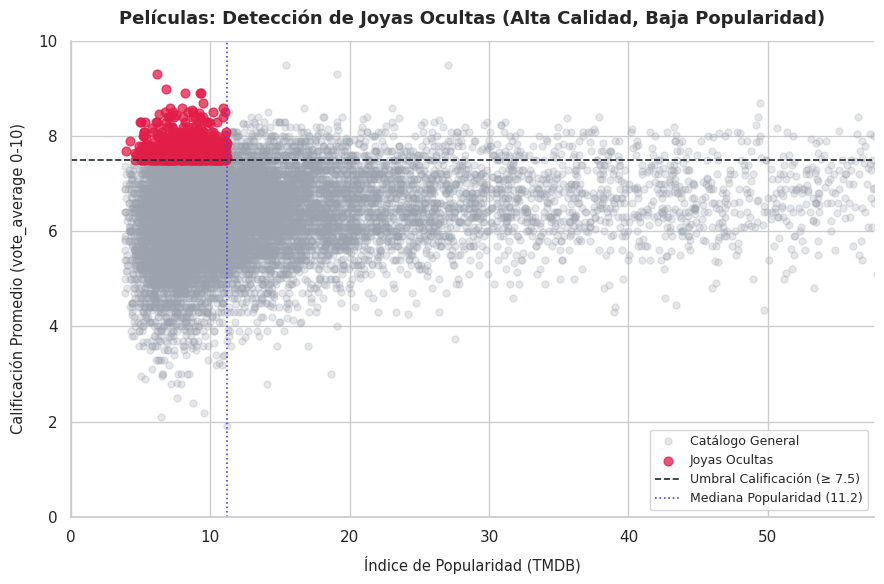

In [30]:
# Configuración de estilo y lienzo individual
sns.set_theme(style='whitegrid')
plt.figure(figsize=(9, 6))

# Datos y umbral de corte
data_pel = peliculas_seg
p_corte_pel = data_pel['umbral_pop'].iloc[0]

# 1. Puntos del catálogo general (fondo en tono neutro)
otros_pel = data_pel[data_pel['segmento'] == 'Otros']
plt.scatter(
    otros_pel['popularity'],
    otros_pel['vote_average'],
    color='#9ca3af',
    alpha=0.25,
    s=25,
    label='Catálogo General'
)

# 2. Puntos destacados: Joyas Ocultas (color de acento)
joyas_pel = data_pel[data_pel['segmento'] == 'Joya Oculta']
plt.scatter(
    joyas_pel['popularity'],
    joyas_pel['vote_average'],
    color='#e11d48',
    alpha=0.75,
    s=40,
    label='Joyas Ocultas'
)

# 3. Líneas de referencia del cuadrante
plt.axhline(7.5, color='#1f2937', linestyle='--', linewidth=1.2, label='Umbral Calificación (≥ 7.5)')
plt.axvline(p_corte_pel, color='#4f46e5', linestyle=':', linewidth=1.2, label=f'Mediana Popularidad ({p_corte_pel:.1f})')

# 4. Ajuste de límites (escala de notas 0 a 10 y corte en p95 para popularidad)
p95_pel = data_pel['popularity'].quantile(0.95)
plt.xlim(0, p95_pel)
plt.ylim(0, 10)

# Títulos, etiquetas y leyenda
plt.title('Películas: Detección de Joyas Ocultas (Alta Calidad, Baja Popularidad)', fontsize=13, weight='bold', pad=12)
plt.xlabel('Índice de Popularidad (TMDB)', fontsize=10.5, labelpad=8)
plt.ylabel('Calificación Promedio (vote_average 0-10)', fontsize=10.5, labelpad=8)
plt.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9)

sns.despine()
plt.tight_layout()
plt.show()

## Cuadrante de joyas Series

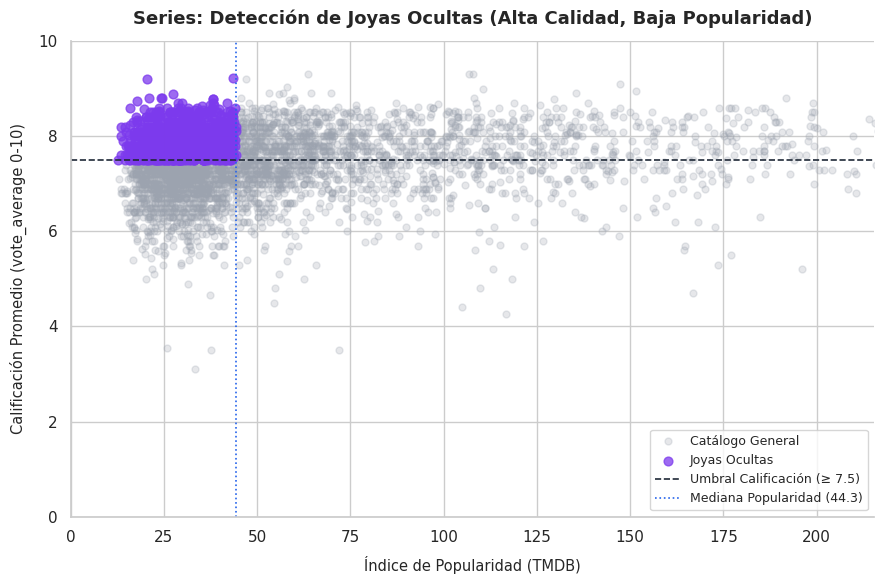

In [31]:
# Configuración de estilo y lienzo individual
sns.set_theme(style='whitegrid')
plt.figure(figsize=(9, 6))

# Datos y umbral de corte
data_ser = series_seg
p_corte_ser = data_ser['umbral_pop'].iloc[0]

# 1. Puntos del catálogo general (fondo en tono neutro)
otros_ser = data_ser[data_ser['segmento'] == 'Otros']
plt.scatter(
    otros_ser['popularity'],
    otros_ser['vote_average'],
    color='#9ca3af',
    alpha=0.25,
    s=25,
    label='Catálogo General'
)

# 2. Puntos destacados: Joyas Ocultas (color de acento)
joyas_ser = data_ser[data_ser['segmento'] == 'Joya Oculta']
plt.scatter(
    joyas_ser['popularity'],
    joyas_ser['vote_average'],
    color='#7c3aed',  # Variación en tono violeta para distinguir el formato de series
    alpha=0.75,
    s=40,
    label='Joyas Ocultas'
)

# 3. Líneas de referencia del cuadrante
plt.axhline(7.5, color='#1f2937', linestyle='--', linewidth=1.2, label='Umbral Calificación (≥ 7.5)')
plt.axvline(p_corte_ser, color='#2563eb', linestyle=':', linewidth=1.2, label=f'Mediana Popularidad ({p_corte_ser:.1f})')

# 4. Ajuste de límites (escala de notas 0 a 10 y corte en p95 para popularidad)
p95_ser = data_ser['popularity'].quantile(0.95)
plt.xlim(0, p95_ser)
plt.ylim(0, 10)

# Títulos, etiquetas y leyenda
plt.title('Series: Detección de Joyas Ocultas (Alta Calidad, Baja Popularidad)', fontsize=13, weight='bold', pad=12)
plt.xlabel('Índice de Popularidad (TMDB)', fontsize=10.5, labelpad=8)
plt.ylabel('Calificación Promedio (vote_average 0-10)', fontsize=10.5, labelpad=8)
plt.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9)

sns.despine()
plt.tight_layout()
plt.show()

# Top 10 Joyas Ocultas Listas para Campaña de Marketing

Entregar a Marketing nombres propios listos para colocar en un carrusel temático (ej. "Aclamadas por la crítica que probablemente te perdiste").

## Top 10 Películas

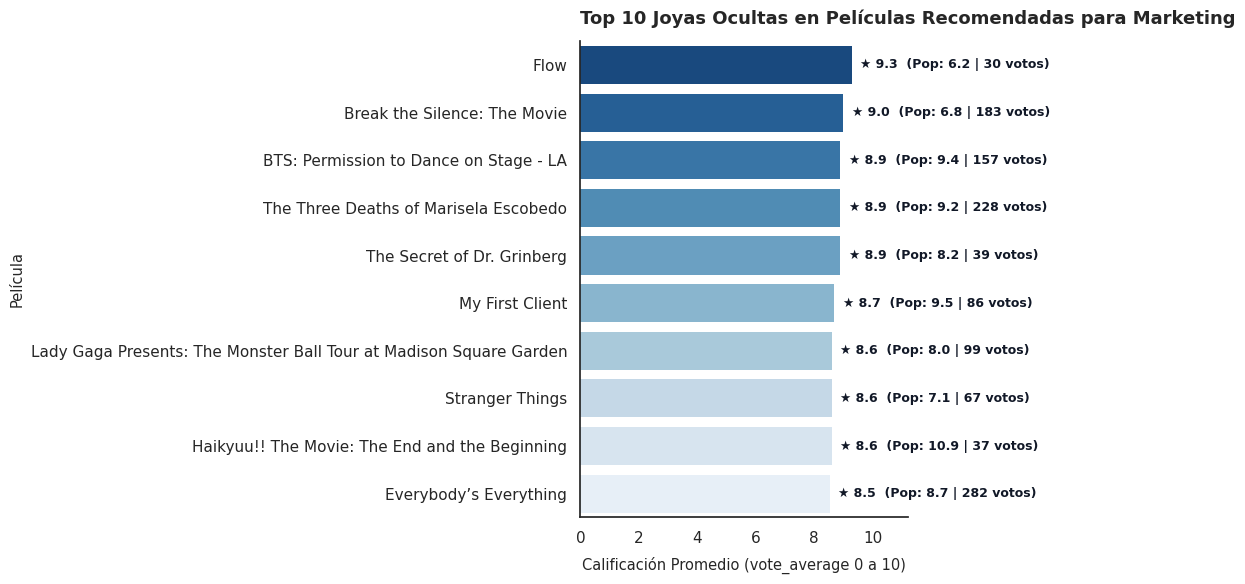

In [32]:
# Selección del Top 10 de películas
top_joyas_pel = joyas_peliculas.head(10).reset_index(drop=True)

# Configuración del lienzo individual
plt.figure(figsize=(10, 6))
sns.set_theme(style='white')

# Gráfico de barras horizontales con degradado azul
ax = sns.barplot(
    data=top_joyas_pel,
    x='vote_average',
    y='title',
    hue='title',
    palette='Blues_r',
    legend=False,
    edgecolor='none'
)

# Etiquetas directas: nota promedio, índice de popularidad y total de votos
for i, bar in enumerate(ax.patches):
    ancho = bar.get_width()
    pop_val = top_joyas_pel.loc[i, 'popularity']
    votos_val = int(top_joyas_pel.loc[i, 'vote_count'])

    ax.annotate(
        f'★ {ancho:.1f}  (Pop: {pop_val:.1f} | {votos_val} votos)',
        (ancho, bar.get_y() + bar.get_height() / 2.0),
        ha='left', va='center', xytext=(6, 0), textcoords='offset points',
        fontsize=9, weight='bold', color='#111827'
    )

# Formato de ejes, títulos y márgenes
plt.title('Top 10 Joyas Ocultas en Películas Recomendadas para Marketing', fontsize=13, weight='bold', loc='left', pad=12)
plt.xlabel('Calificación Promedio (vote_average 0 a 10)', fontsize=10.5, labelpad=8)
plt.ylabel('Película', fontsize=10.5)
plt.xlim(0, 11.2)  # Margen ampliado para evitar corte del texto

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

## Top 10 Series

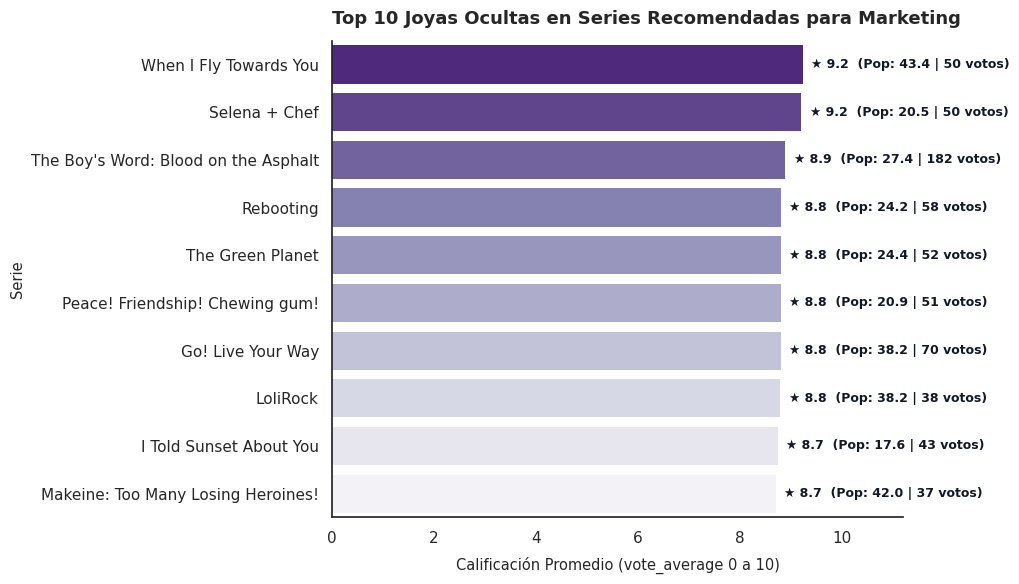

In [33]:
# Selección del Top 10 de series
top_joyas_ser = joyas_series.head(10).reset_index(drop=True)

# Configuración del lienzo individual
plt.figure(figsize=(10, 6))
sns.set_theme(style='white')

# Gráfico de barras horizontales con paleta en tonos púrpura
ax = sns.barplot(
    data=top_joyas_ser,
    x='vote_average',
    y='title',
    hue='title',
    palette='Purples_r',
    legend=False,
    edgecolor='none'
)

# Etiquetas directas: nota promedio, índice de popularidad y total de votos
for i, bar in enumerate(ax.patches):
    ancho = bar.get_width()
    pop_val = top_joyas_ser.loc[i, 'popularity']
    votos_val = int(top_joyas_ser.loc[i, 'vote_count'])

    ax.annotate(
        f'★ {ancho:.1f}  (Pop: {pop_val:.1f} | {votos_val} votos)',
        (ancho, bar.get_y() + bar.get_height() / 2.0),
        ha='left', va='center', xytext=(6, 0), textcoords='offset points',
        fontsize=9, weight='bold', color='#111827'
    )

# Formato de ejes, títulos y márgenes
plt.title('Top 10 Joyas Ocultas en Series Recomendadas para Marketing', fontsize=13, weight='bold', loc='left', pad=12)
plt.xlabel('Calificación Promedio (vote_average 0 a 10)', fontsize=10.5, labelpad=8)
plt.ylabel('Serie', fontsize=10.5)
plt.xlim(0, 11.2)  # Margen ampliado para evitar corte del texto

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

# Concentración por Género de las Joyas Ocultas

Objetivo: Descubrir qué categorías concentran más tesoros desaprovechados (ej. Documentales, Animación, Cine Independiente, Thrillers) para enfocar campañas segmentadas.

## Géneros de joyas películas

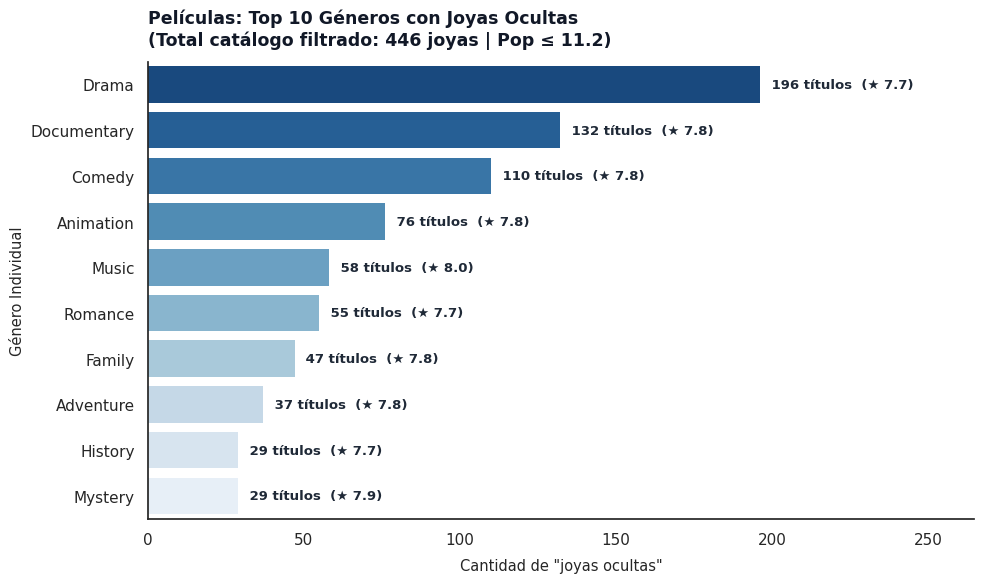

In [34]:
# Configuración del lienzo individual
plt.figure(figsize=(10, 6))
sns.set_theme(style='white')

# Gráfico de barras horizontales (Blues_r)
ax = sns.barplot(
    data=top_pel,
    x='total_joyas',
    y='genero_individual',
    hue='genero_individual',
    palette='Blues_r',
    legend=False,
    edgecolor='none'
)

# Etiquetas directas al final de cada barra (conteo y calificación media)
max_valor_pel = top_pel['total_joyas'].max()
for i, bar in enumerate(ax.patches):
    ancho = bar.get_width()
    nota_media = top_pel.loc[i, 'nota_promedio']
    ax.annotate(
        f' {int(ancho)} títulos  (★ {nota_media:.1f})',
        (ancho, bar.get_y() + bar.get_height() / 2.0),
        ha='left', va='center', xytext=(5, 0), textcoords='offset points',
        fontsize=9.5, weight='bold', color='#1f2937'
    )

# Títulos, ejes y márgenes
plt.title(
    f'Películas: Top 10 Géneros con Joyas Ocultas\n'
    f'(Total catálogo filtrado: {total_joyas_pel} joyas | Pop ≤ {corte_pop_pel:.1f})',
    fontsize=12.5, weight='bold', loc='left', pad=12, color='#111827'
)
plt.xlabel('Cantidad de "joyas ocultas"', fontsize=10.5, labelpad=8)
plt.ylabel('Género Individual', fontsize=10.5)
plt.xlim(0, max_valor_pel * 1.35)  # Espacio para evitar corte de texto

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

## Géneros de joyas series

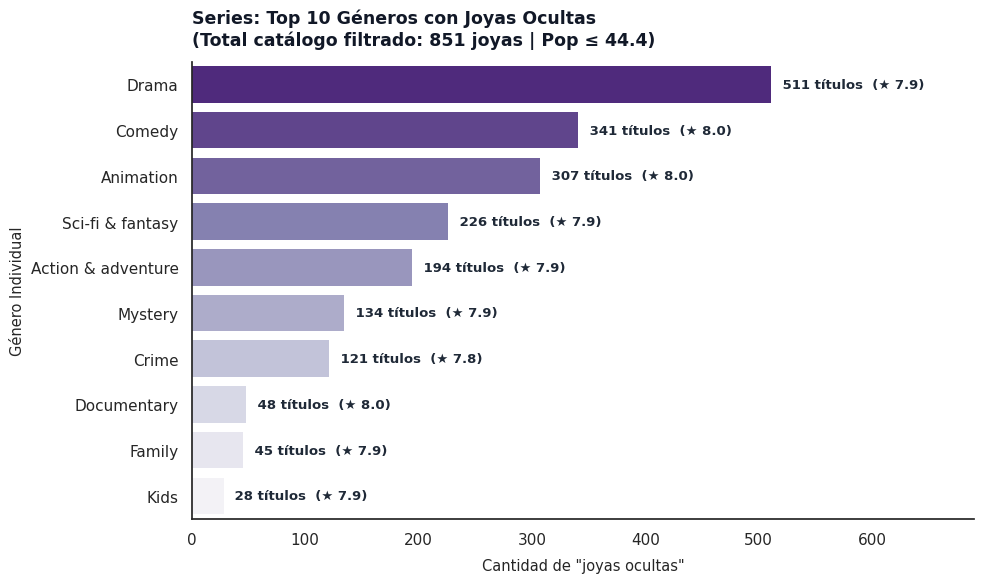

In [35]:
# Configuración del lienzo individual
plt.figure(figsize=(10, 6))
sns.set_theme(style='white')

# Gráfico de barras horizontales (Purples_r)
ax = sns.barplot(
    data=top_ser,
    x='total_joyas',
    y='genero_individual',
    hue='genero_individual',
    palette='Purples_r',
    legend=False,
    edgecolor='none'
)

# Etiquetas directas al final de cada barra (conteo y calificación media)
max_valor_ser = top_ser['total_joyas'].max()
for i, bar in enumerate(ax.patches):
    ancho = bar.get_width()
    nota_media = top_ser.loc[i, 'nota_promedio']
    ax.annotate(
        f' {int(ancho)} títulos  (★ {nota_media:.1f})',
        (ancho, bar.get_y() + bar.get_height() / 2.0),
        ha='left', va='center', xytext=(5, 0), textcoords='offset points',
        fontsize=9.5, weight='bold', color='#1f2937'
    )

# Títulos, ejes y márgenes
plt.title(
    f'Series: Top 10 Géneros con Joyas Ocultas\n'
    f'(Total catálogo filtrado: {total_joyas_ser} joyas | Pop ≤ {corte_pop_ser:.1f})',
    fontsize=12.5, weight='bold', loc='left', pad=12, color='#111827'
)
plt.xlabel('Cantidad de "joyas ocultas"', fontsize=10.5, labelpad=8)
plt.ylabel('Género Individual', fontsize=10.5)
plt.xlim(0, max_valor_ser * 1.35)  # Espacio para evitar corte de texto

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

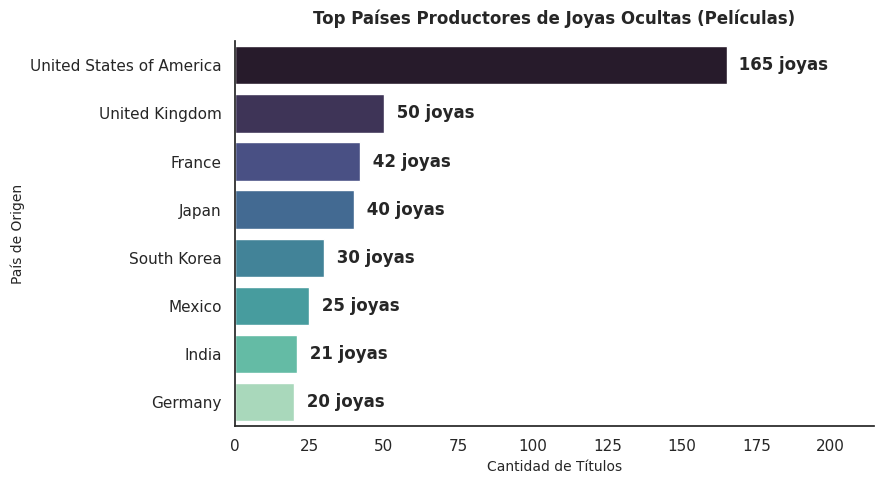

In [36]:
#CONCENTRACIÓN DE JOYAS POR PAÍS DE ORIGEN
# Separación de países (por comas si hay coproducciones)
joyas_paises = joyas_peliculas.copy()
joyas_paises['pais_lista'] = joyas_paises['country'].dropna().astype(str).apply(
    lambda x: [c.strip() for c in x.split(',') if c.strip()]
)
top_paises = joyas_paises.explode('pais_lista')['pais_lista'].value_counts().head(8).reset_index()
top_paises.columns = ['pais', 'total_joyas']

plt.figure(figsize=(9, 5))
sns.barplot(data=top_paises, x='total_joyas', y='pais', hue='pais', palette='mako', legend=False)
for i, bar in enumerate(plt.gca().patches):
    w = bar.get_width()
    plt.annotate(f' {int(w)} joyas', (w, bar.get_y() + bar.get_height() / 2.0),
                 ha='left', va='center', xytext=(5, 0), textcoords='offset points', weight='bold')

plt.title('Top Países Productores de Joyas Ocultas (Películas)', fontsize=12, weight='bold', pad=12)
plt.xlabel('Cantidad de Títulos', fontsize=10)
plt.ylabel('País de Origen', fontsize=10)
plt.xlim(0, top_paises['total_joyas'].max() * 1.3)
sns.despine()
plt.tight_layout()
plt.show()

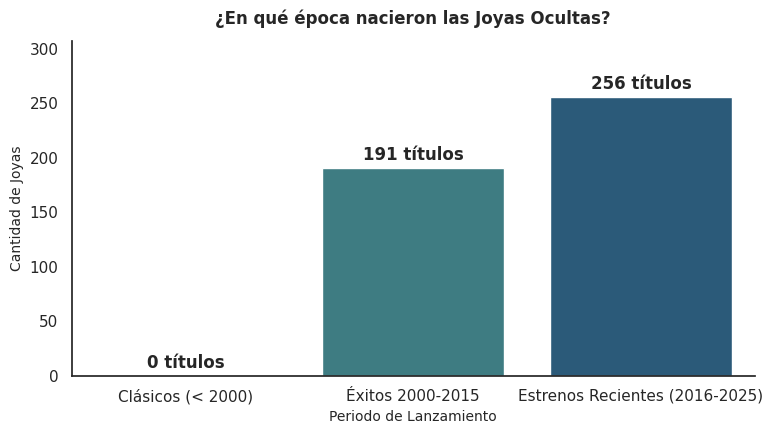

In [37]:
df_tiempo = joyas_peliculas.copy()
df_tiempo['epoca'] = pd.cut(
    df_tiempo['release_year'],
    bins=[1900, 1999, 2015, 2025],
    labels=['Clásicos (< 2000)', 'Éxitos 2000-2015', 'Estrenos Recientes (2016-2025)']
)
conteo_epocas = df_tiempo['epoca'].value_counts().reset_index()
conteo_epocas.columns = ['epoca', 'total']

plt.figure(figsize=(8, 4.5))
sns.barplot(data=conteo_epocas, x='epoca', y='total', hue='epoca', palette='crest', legend=False)
for bar in plt.gca().patches:
    h = bar.get_height()
    plt.annotate(f'{int(h)} títulos', (bar.get_x() + bar.get_width() / 2.0, h),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', weight='bold')

plt.title('¿En qué época nacieron las Joyas Ocultas?', fontsize=12, weight='bold', pad=12)
plt.xlabel('Periodo de Lanzamiento', fontsize=10)
plt.ylabel('Cantidad de Joyas', fontsize=10)
plt.ylim(0, conteo_epocas['total'].max() * 1.2)
sns.despine()
plt.tight_layout()
plt.show()

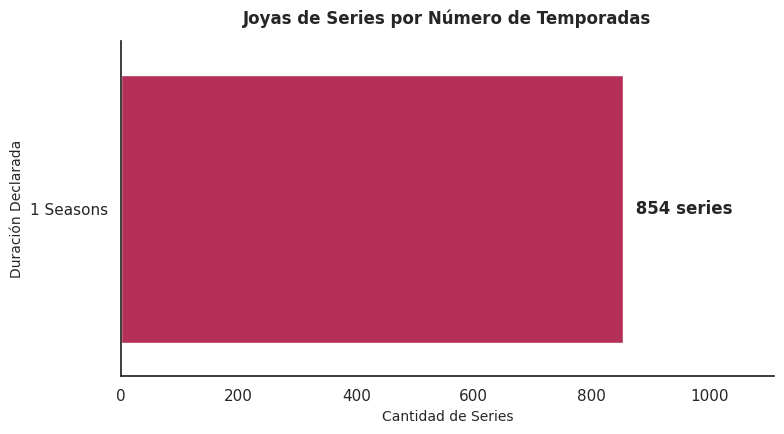

In [38]:
df_dur_series = joyas_series.copy()
top_temporadas = df_dur_series['duration'].value_counts().head(5).reset_index()
top_temporadas.columns = ['temporadas', 'total']

plt.figure(figsize=(8, 4.5))
sns.barplot(data=top_temporadas, x='total', y='temporadas', hue='temporadas', palette='rocket_r', legend=False)
for bar in plt.gca().patches:
    w = bar.get_width()
    plt.annotate(f' {int(w)} series', (w, bar.get_y() + bar.get_height() / 2.0),
                 ha='left', va='center', xytext=(5, 0), textcoords='offset points', weight='bold')

plt.title('Joyas de Series por Número de Temporadas', fontsize=12, weight='bold', pad=12)
plt.xlabel('Cantidad de Series', fontsize=10)
plt.ylabel('Duración Declarada', fontsize=10)
plt.xlim(0, top_temporadas['total'].max() * 1.3)
sns.despine()
plt.tight_layout()
plt.show()

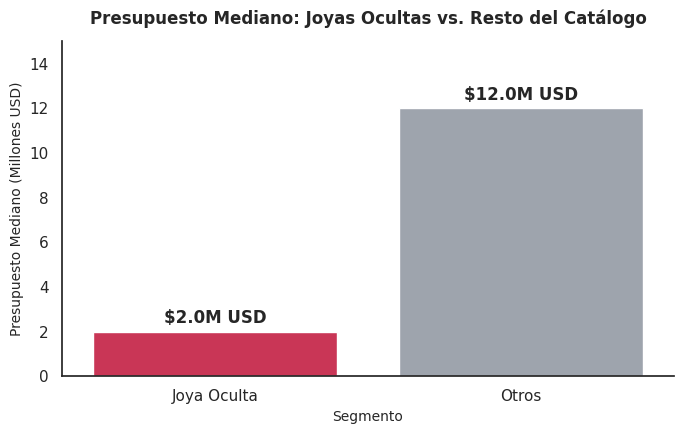

In [39]:
df_pel_fin = peliculas_seg[(peliculas_seg['budget'] > 0)].copy()

comparativa = df_pel_fin.groupby('segmento')['budget'].median().reset_index()
comparativa['budget_millones'] = comparativa['budget'] / 1e6

plt.figure(figsize=(7, 4.5))
sns.barplot(data=comparativa, x='segmento', y='budget_millones', hue='segmento', palette=['#e11d48', '#9ca3af'], legend=False)
for bar in plt.gca().patches:
    h = bar.get_height()
    plt.annotate(f'${h:.1f}M USD', (bar.get_x() + bar.get_width() / 2.0, h),
                 ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', weight='bold')

plt.title('Presupuesto Mediano: Joyas Ocultas vs. Resto del Catálogo', fontsize=12, weight='bold', pad=12)
plt.ylabel('Presupuesto Mediano (Millones USD)', fontsize=10)
plt.xlabel('Segmento', fontsize=10)
plt.ylim(0, comparativa['budget_millones'].max() * 1.25)
sns.despine()
plt.tight_layout()
plt.show()